Connect google drive.

In [75]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Get the dataset

In [76]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/220105_AI_ML/Task_2_Linear_&_Logistic_Regression/Titanic-Dataset.csv')

## **Lets explore our dataset and try to  understand relations between columns**

Get a first look at the data

In [77]:
print("Shape:", df.shape)
print("\nFirst 5 rows:")
df.head()

Shape: (891, 12)

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Get basic info about data

In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


Lets view some statistical data about our dataset.

In [79]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


Lets check for missing values

In [80]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Lets try to find out if our model is equally distributed towards both outcome

In [81]:
print("Survival Count:")
print(df['Survived'].value_counts())
print("\nSurvival Percentage:")
print(df['Survived'].value_counts(normalize=True) * 100)

Survival Count:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentage:
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


Now, we will visualize the relations between different columns and the survival

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

Lets plot the survival count

/tmp/ipykernel_1168/2957924010.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived', data=df, palette='Set2')


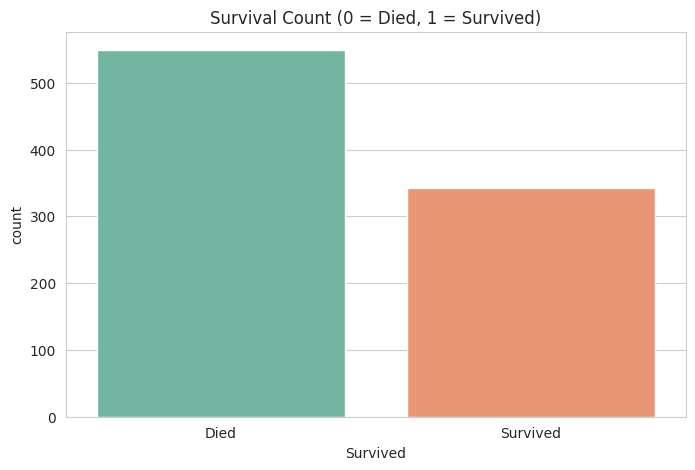

In [83]:
sns.countplot(x='Survived', data=df, palette='Set2')
plt.title('Survival Count (0 = Died, 1 = Survived)')
plt.xticks([0, 1], ['Died', 'Survived'])
plt.show()

Lets see survival based on gender

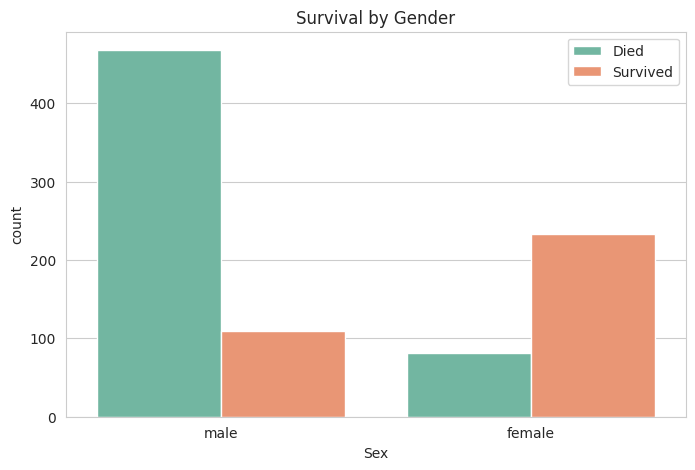

In [84]:
sns.countplot(x='Sex', hue='Survived', data=df, palette='Set2')
plt.title('Survival by Gender')
plt.legend(['Died', 'Survived'])
plt.show()

Lets see if passenger class any effect over survival

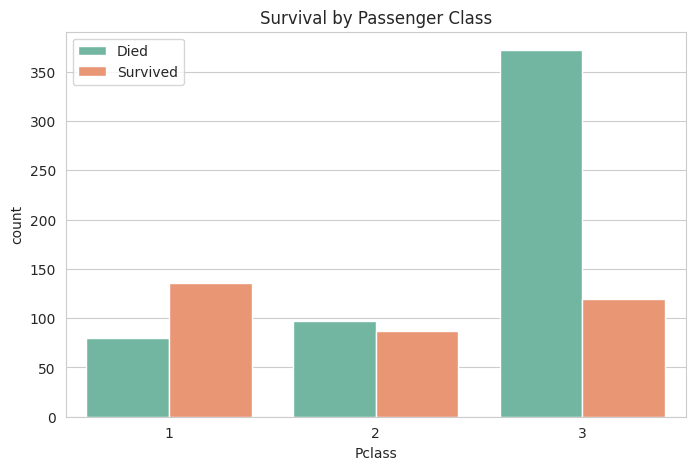

In [85]:
sns.countplot(x='Pclass', hue='Survived', data=df, palette='Set2')
plt.title('Survival by Passenger Class')
plt.legend(['Died', 'Survived'])
plt.show()

Lets see if age has any effect over survival

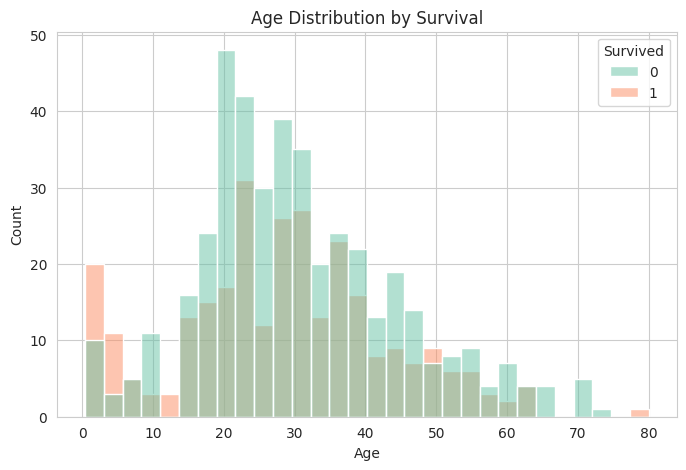

In [86]:
sns.histplot(data=df, x='Age', hue='Survived', bins=30,
             kde=False, palette='Set2')
plt.title('Age Distribution by Survival')
plt.show()

Lets see a correlation heatmap

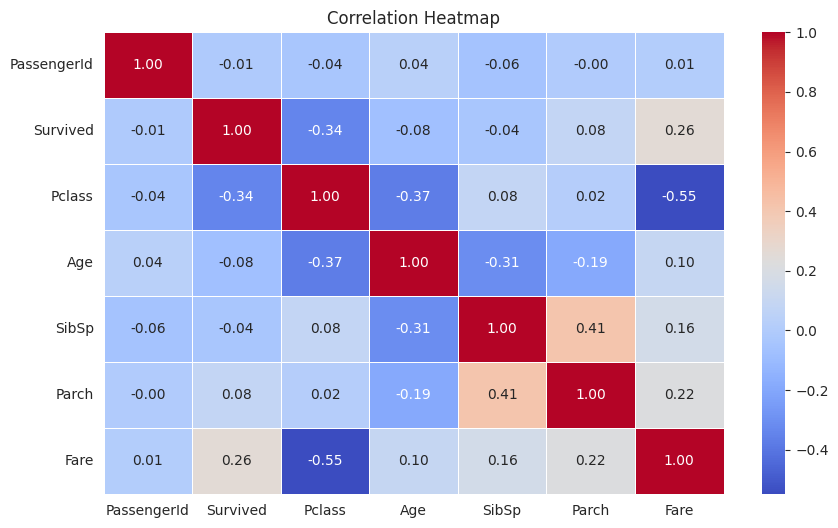

In [87]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True),
            annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap')
plt.show()

Some people on the titanic were with families. We will try to visualize the relation between survival rate on the family size. First we will create a new column named family size.

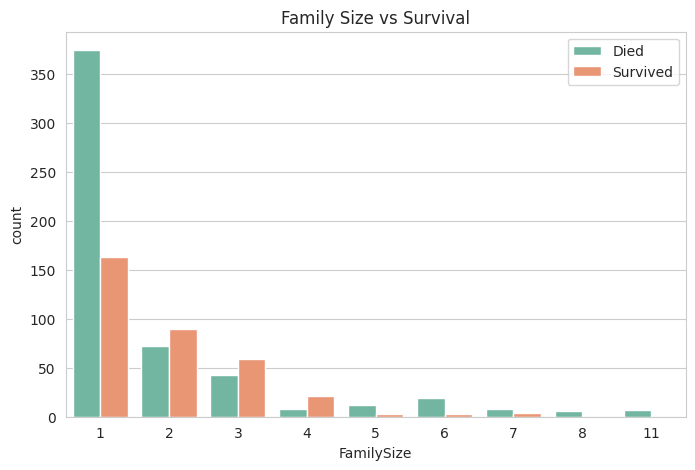

In [88]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

sns.countplot(x='FamilySize', hue='Survived', data=df, palette='Set2')
plt.title('Family Size vs Survival')
plt.legend(['Died', 'Survived'])
plt.show()

# **Now, we will perform data preprocessing.**

The first step will be to remove unnecessary columns that should not have any effect over survival.

In [89]:

df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

print("Remaining columns:", df.columns.tolist())

Remaining columns: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize']


Previously we found out that age and embarked has some missing values, we have to handle them.

We will fill missing places of age with the median.

In [90]:
df['Age'].fillna(df['Age'].median(), inplace=True)

/tmp/ipykernel_1168/1933487976.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)


We will fill missing places of embarked with the most common port.

In [91]:
df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)

/tmp/ipykernel_1168/3744086084.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Embarked'].fillna(df['Embarked'].mode()[0], inplace=True)


Lets confirm there are no missing values left.

In [92]:
print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
FamilySize    0
dtype: int64


Now, we need to conert categorical data to numeric data. Cause machine can accept numeric data.

In [93]:
df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

print("After encoding:")
df.head()

After encoding:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
0,0,3,0,22.0,1,0,7.2500,0,2
1,1,1,1,38.0,1,0,71.2833,1,2
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,2
4,0,3,0,35.0,0,0,8.0500,0,1


Now, we will add some more columns based on out initial columns to make our model more accurate.

Before adding these two columns, results were


```
=============================================
   VALIDATION vs TEST COMPARISON
=============================================
Metric         Validation         Test
---------------------------------------------
Accuracy           0.7978       0.7933
Precision          0.7500       0.7667
Recall             0.7059       0.6667
F1 Score           0.7273       0.7132
AUC                0.8582       0.8386
=============================================
```



In [94]:
df['Age_Pclass']     = df['Age'] * df['Pclass'] #This one is the multiplication of age and passenger class
df['FarePerPerson']  = df['Fare'] / df['FamilySize'] #Some passengers are single and some are family, this data is the average of fare per family member

Now, we will normalize the numeric features, so thet the model doesnt think, one feature is more important than others.

In [95]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

cols_to_scale = ['Age', 'Fare', 'FamilySize', 'Age_Pclass', 'FarePerPerson']

df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

print("After scaling:")
df.head()

After scaling:


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,Age_Pclass,FarePerPerson
0,0,3,0,-0.565736,1,0,-0.502445,0,0.059160,0.058824,-0.454798
1,1,1,1,0.663861,1,0,0.786845,1,0.059160,-0.803342,0.438994
2,1,3,1,-0.258337,0,0,-0.488854,0,-0.560975,0.428324,-0.334757
3,1,1,1,0.433312,1,0,0.420730,0,0.059160,-0.895717,0.185187
4,0,3,0,0.433312,0,0,-0.486337,0,-0.560975,1.259699,-0.331267


Now, we will split the dataset into features and target.

In [96]:
X = df.drop(columns=['Survived'])
y = df['Survived']

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:", X.columns.tolist())

Features shape: (891, 10)
Target shape: (891,)

Feature columns: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'Age_Pclass', 'FarePerPerson']


Now we will split the data into trining data, validation data and testing data.

At first we will split the data into 80%-20%.

The 20% data will be our testing data.

From the other data, we will take it's 75% off as training data, and the rest 25% will be our validation data.

In [97]:
from sklearn.model_selection import train_test_split

# First split: 80% train+val, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Second split: 75% train, 25% validation (of the 80%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

print("Training set size:  ", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:      ", X_test.shape[0])

Training set size:   534
Validation set size: 178
Test set size:       179


# **Below here is model training and validation part**

Now we will train the model over the training set.

In [98]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(random_state=42, max_iter=1000)

model.fit(X_train, y_train)

print("Model training complete!")

Model training complete!


Now, using the validation set we will generate predictions. We will generate outcome and their probablities also.

In [99]:
y_val_pred = model.predict(X_val)

y_val_prob = model.predict_proba(X_val)[:, 1]

print("Predictions done!")
print("\nSample predictions vs actual:")
print("Predicted:", y_val_pred[:10])
print("Actual:   ", y_val.values[:10])

Predictions done!

Sample predictions vs actual:
Predicted: [0 0 1 0 0 0 0 1 0 0]
Actual:    [0 0 1 0 0 0 0 1 0 0]


Lets find out vlidation accuracy.

In [100]:
from sklearn.metrics import accuracy_score

val_accuracy = accuracy_score(y_val, y_val_pred)
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Validation Accuracy: 80.34%


Lets check model co efficients. This will indicate which features matter more.

In [101]:
import pandas as pd

coefficients = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_[0]
}).sort_values('Coefficient', ascending=False)

print(coefficients)

         Feature  Coefficient
1            Sex     2.495314
6       Embarked     0.366757
5           Fare     0.362406
4          Parch    -0.013198
7     FamilySize    -0.110207
3          SibSp    -0.164797
9  FarePerPerson    -0.181037
8     Age_Pclass    -0.265216
2            Age    -0.303830
0         Pclass    -0.853760


# **Now, we will see some evaluation metrics of validation**

The first step would be to generate the confusion matrix heatmap to understand how much of the predictions are True Positive, True Negative, False Positive and False Negative.

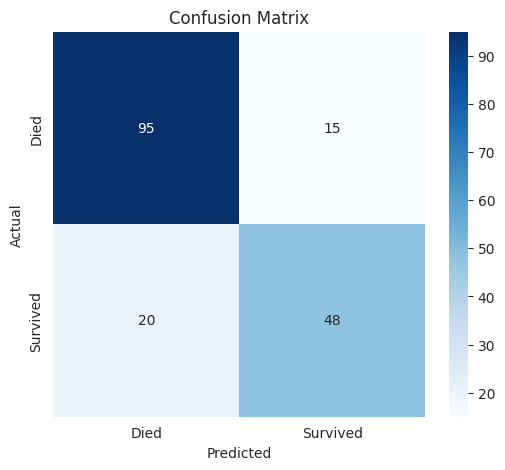

In [102]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_val, y_val_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Died', 'Survived'],
            yticklabels=['Died', 'Survived'])
plt.title('Confusion Matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Lets print other statictical metrics.

In [103]:
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             classification_report)

print("=" * 40)
print("       EVALUATION METRICS")
print("=" * 40)
print(f"Accuracy : {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred):.4f}")
print(f"Recall   : {recall_score(y_val, y_val_pred):.4f}")
print(f"F1 Score : {f1_score(y_val, y_val_pred):.4f}")
print(f"AUC      : {roc_auc_score(y_val, y_val_prob):.4f}")
print("=" * 40)
print("\nDetailed Report:")
print(classification_report(y_val, y_val_pred,
                            target_names=['Died', 'Survived']))

       EVALUATION METRICS
Accuracy : 0.8034
Precision: 0.7619
Recall   : 0.7059
F1 Score : 0.7328
AUC      : 0.8565

Detailed Report:
              precision    recall  f1-score   support

        Died       0.83      0.86      0.84       110
    Survived       0.76      0.71      0.73        68

    accuracy                           0.80       178
   macro avg       0.79      0.78      0.79       178
weighted avg       0.80      0.80      0.80       178



Lets print a ROC curve

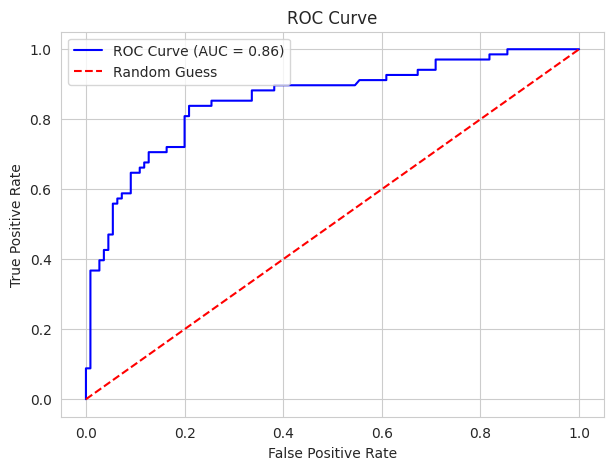

In [104]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)
auc_score = roc_auc_score(y_val, y_val_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='blue',
         label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='red',
         linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

Lets view some of the sample predictions

In [105]:
import numpy as np

results = pd.DataFrame({
    'Actual'     : y_val.values,
    'Predicted'  : y_val_pred,
    'Probability': np.round(y_val_prob, 3)
})

results['Actual']    = results['Actual'].map({0:'Died', 1:'Survived'})
results['Predicted'] = results['Predicted'].map({0:'Died', 1:'Survived'})
results['Correct']   = results['Actual'] == results['Predicted']

print("Sample Predictions (first 15):")
print(results.head(15).to_string(index=False))

Sample Predictions (first 15):
  Actual Predicted  Probability  Correct
    Died      Died        0.114     True
    Died      Died        0.124     True
Survived  Survived        0.781     True
    Died      Died        0.105     True
    Died      Died        0.088     True
    Died      Died        0.105     True
    Died      Died        0.088     True
Survived  Survived        0.949     True
    Died      Died        0.084     True
    Died      Died        0.324     True
Survived  Survived        0.504     True
Survived      Died        0.399    False
    Died  Survived        0.575    False
Survived  Survived        0.898     True
    Died      Died        0.037     True


# **Below here is testing on the test set**

In [106]:
y_test_pred = model.predict(X_test)
y_test_prob = model.predict_proba(X_test)[:, 1]

print("Test set predictions done!")
print(f"Total test samples: {len(y_test)}")

Test set predictions done!
Total test samples: 179


## **Now we will see the evaluation metrics on the test set predictions**

First, we take a look at our final confusion matrix heatmap

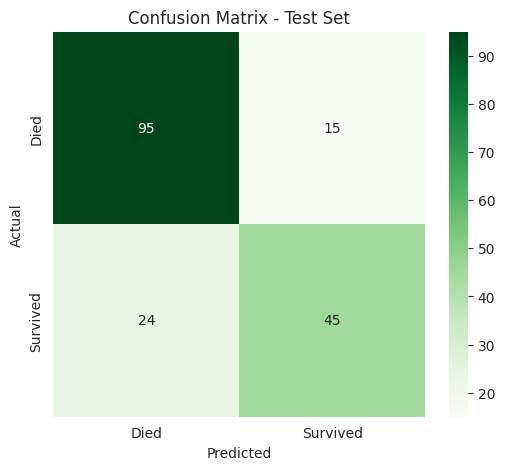

In [107]:
cm_test = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Died', 'Survived'],
            yticklabels=['Died', 'Survived'])
plt.title('Confusion Matrix - Test Set')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

Lets take a look at our final metrics

In [108]:
print("=" * 40)
print("     FINAL TEST SET METRICS")
print("=" * 40)
print(f"Accuracy : {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_test_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_test_pred):.4f}")
print(f"F1 Score : {f1_score(y_test, y_test_pred):.4f}")
print(f"AUC      : {roc_auc_score(y_test, y_test_prob):.4f}")
print("=" * 40)
print("\nDetailed Report:")
print(classification_report(y_test, y_test_pred,
                            target_names=['Died', 'Survived']))

     FINAL TEST SET METRICS
Accuracy : 0.7821
Precision: 0.7500
Recall   : 0.6522
F1 Score : 0.6977
AUC      : 0.8385

Detailed Report:
              precision    recall  f1-score   support

        Died       0.80      0.86      0.83       110
    Survived       0.75      0.65      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179



And this is out final ROC curve

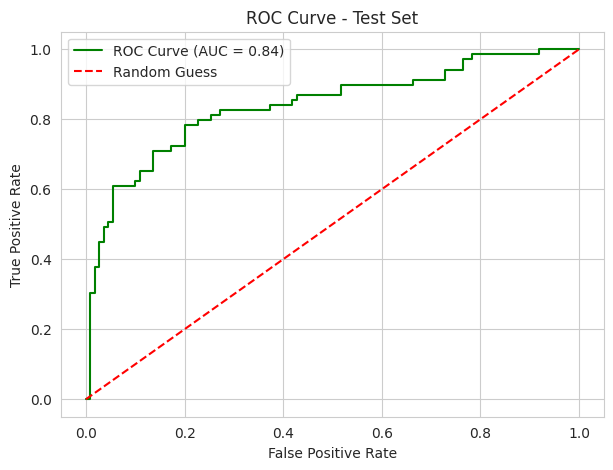

In [109]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
auc_score = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, color='green',
         label=f'ROC Curve (AUC = {auc_score:.2f})')
plt.plot([0, 1], [0, 1], color='red',
         linestyle='--', label='Random Guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend()
plt.show()

Lets compare validation vs test data

In [110]:
print("=" * 45)
print("   VALIDATION vs TEST COMPARISON")
print("=" * 45)
print(f"{'Metric':<12} {'Validation':>12} {'Test':>12}")
print("-" * 45)
print(f"{'Accuracy':<12} {accuracy_score(y_val, y_val_pred):>12.4f} {accuracy_score(y_test, y_test_pred):>12.4f}")
print(f"{'Precision':<12} {precision_score(y_val, y_val_pred):>12.4f} {precision_score(y_test, y_test_pred):>12.4f}")
print(f"{'Recall':<12} {recall_score(y_val, y_val_pred):>12.4f} {recall_score(y_test, y_test_pred):>12.4f}")
print(f"{'F1 Score':<12} {f1_score(y_val, y_val_pred):>12.4f} {f1_score(y_test, y_test_pred):>12.4f}")
print(f"{'AUC':<12} {roc_auc_score(y_val, y_val_prob):>12.4f} {roc_auc_score(y_test, y_test_prob):>12.4f}")
print("=" * 45)

   VALIDATION vs TEST COMPARISON
Metric         Validation         Test
---------------------------------------------
Accuracy           0.8034       0.7821
Precision          0.7619       0.7500
Recall             0.7059       0.6522
F1 Score           0.7328       0.6977
AUC                0.8565       0.8385


Now, we will view some sample predictions over test data.

In [112]:
import numpy as np

results = pd.DataFrame({
    'Actual'     : y_test.values,
    'Predicted'  : y_test_pred,
    'Probability': np.round(y_test_prob, 3)
})

results['Actual']    = results['Actual'].map({0:'Died', 1:'Survived'})
results['Predicted'] = results['Predicted'].map({0:'Died', 1:'Survived'})
results['Correct']   = results['Actual'] == results['Predicted']

print("Sample Predictions (first 15):")
print(results.head(15).to_string(index=False))

Sample Predictions (first 15):
  Actual Predicted  Probability  Correct
    Died      Died        0.076     True
    Died      Died        0.042     True
Survived      Died        0.156    False
    Died      Died        0.033     True
Survived  Survived        0.671     True
Survived      Died        0.403    False
Survived  Survived        0.718     True
    Died      Died        0.339     True
    Died      Died        0.455     True
    Died      Died        0.165     True
    Died      Died        0.167     True
    Died      Died        0.105     True
Survived  Survived        0.551     True
    Died      Died        0.243     True
    Died  Survived        0.716    False
